In [ ]:
# =========================================
# 🔧 GOOGLE DRIVE SETUP
# =========================================

from google.colab import drive
import os
#ciao
#spero funzioni
# 1️⃣ Monta Google Drive
drive.mount('/content/drive')

# 2️⃣ Imposta il percorso della cartella condivisa (aggiorna il nome se diverso)
shared_folder = "/content/drive/MyDrive/Microwave AI"

# 3️⃣ Controlla se la cartella esiste e spostati al suo interno
if os.path.exists(shared_folder):
    os.chdir(shared_folder)
    print(f"✅ Cartella impostata correttamente:\n{os.getcwd()}")
else:
    print("❌ La cartella 'Microwave AI' non è nel tuo 'Il mio Drive'.")
    print("👉 Vai su Google Drive → 'Condivisi con me' → clic destro sulla cartella → 'Aggiungi a Il mio Drive'.")


In [2]:
# =========================================
# 🔧 LIBRARIES IMPORT
# =========================================


# Set seed for reproducibility
SEED = 69

# Import necessary libraries
import os
import csv

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline


PyTorch version: 2.8.0+cu126
Device: cuda


In [3]:
# =========================================
# 📊 DATA LOADING
# =========================================

# Load the datasets/DataFrames
try:
    train_df = pd.read_csv('pirate_pain_train.csv')
    train_labels_df = pd.read_csv('pirate_pain_train_labels.csv')
    test_df = pd.read_csv('pirate_pain_test.csv')
    submission_df = pd.read_csv('sample_submission.csv')
    print("✅ Datasets loaded successfully!")

except FileNotFoundError as e:
    print(f"❌ Error loading datasets: {e}")
    print("Please ensure the CSV files are in the correct directory.")
    print("Current working directory:", os.getcwd())

except Exception as e:
    print(f"❌ An unexpected error occurred during data loading: {e}")

✅ Datasets loaded successfully!


DATA OVERVIEW
Train shape: (105760, 40)
Labels shape: (661, 2)
Test shape: (211840, 40)

📊 Number of sequences:
   Train: 661
   Test: 1324
label
no_pain      511
low_pain      94
high_pain     56
Name: count, dtype: int64
label
no_pain      77.307110
low_pain     14.220877
high_pain     8.472012
Name: count, dtype: float64


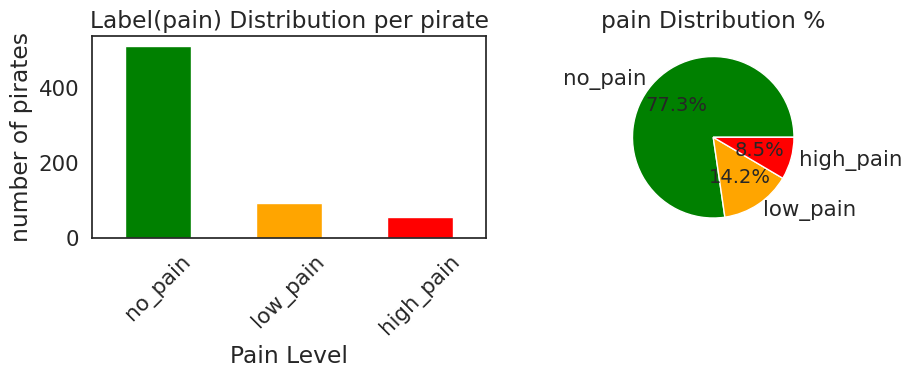

In [4]:
# ====================================================================
# STEP 3: LOAD AND EXPLORE DATA
# ====================================================================

# Load data
train_df = pd.read_csv('pirate_pain_train.csv')
labels_df = pd.read_csv('pirate_pain_train_labels.csv')
test_df = pd.read_csv('pirate_pain_test.csv')

# Remove rows with any missing values
train_df.dropna(axis=0, how='any', inplace=True)
labels_df.dropna(axis=0, how='any', inplace=True)
test_df.dropna(axis=0, how='any', inplace=True)

# Display basic information about the DataFrames
print("=" * 40)
print("DATA OVERVIEW")
print("=" * 40)
print(f"Train shape: {train_df.shape}")
print(f"Labels shape: {labels_df.shape}")
print(f"Test shape: {test_df.shape}")

# Check unique samples(unique pirates)
n_train_samples = train_df['sample_index'].nunique()
n_test_samples = test_df['sample_index'].nunique()
print(f"\n📊 Number of sequences:")
print(f"   Train: {n_train_samples}")
print(f"   Test: {n_test_samples}")

# Check class distribution
label_counts = labels_df['label'].value_counts()
print(label_counts)
print(label_counts / len(labels_df) * 100)

# Visualize class distribution
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
label_counts.plot(kind='bar', color=['green', 'orange', 'red'])
plt.title('Label(pain) Distribution per pirate')
plt.xlabel('Pain Level')
plt.ylabel('number of pirates')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
label_counts.plot(kind='pie', autopct='%1.1f%%', colors=['green', 'orange', 'red'])
plt.title('pain Distribution %')
plt.ylabel('')
plt.tight_layout()
plt.show()

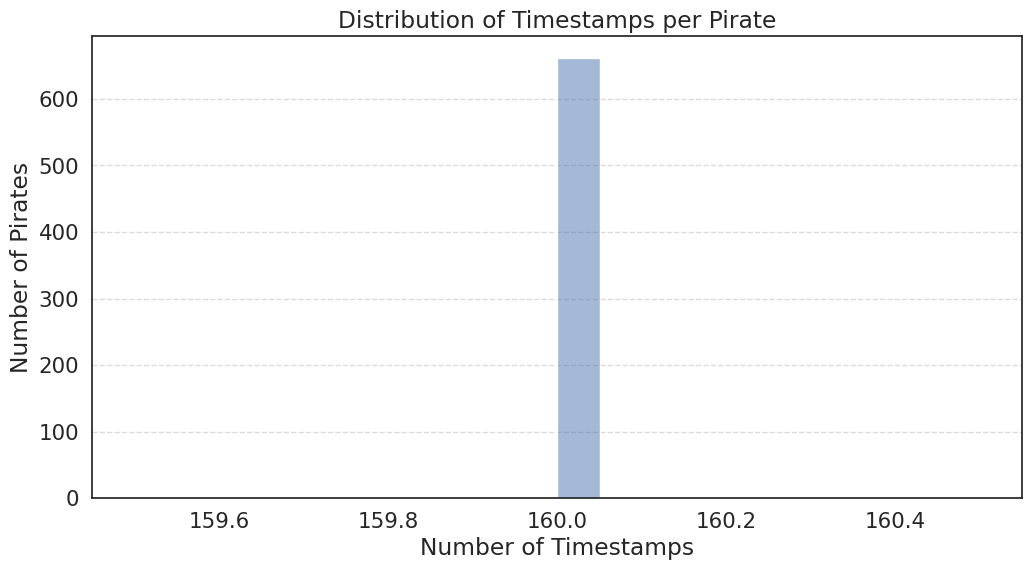

Descriptive statistics for timestamps per pirate:
count    661.0
mean     160.0
std        0.0
min      160.0
25%      160.0
50%      160.0
75%      160.0
max      160.0
Name: time, dtype: float64


In [5]:
# Calculate the number of timestamps for each unique pirate (sample_index)
timestamps_per_pirate = train_df.groupby('sample_index')['time'].count()

# Create a histogram of these counts
plt.figure(figsize=(12, 6))
sns.histplot(timestamps_per_pirate, bins=20, kde=True)
plt.title('Distribution of Timestamps per Pirate')
plt.xlabel('Number of Timestamps')
plt.ylabel('Number of Pirates')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Display some descriptive statistics for context
print("Descriptive statistics for timestamps per pirate:")
print(timestamps_per_pirate.describe())

In [6]:
# ====================================================================
# NUMBER OF PIRATES WITH ONE HAND, EYE OR LEG
# ====================================================================

body_parts = ['n_legs', 'n_hands', 'n_eyes']

for parte in body_parts:
    distribuzione = train_df.groupby('sample_index')[parte].first().value_counts().sort_index()

    print(f"\nDistribuzione del numero di {parte.split('_')[1]} per pirata (Train set):")
    for numero, quanti_pirati in distribuzione.items():
        print(f"{numero}: {quanti_pirati} pirati")


Distribuzione del numero di legs per pirata (Train set):
one+peg_leg: 6 pirati
two: 655 pirati

Distribuzione del numero di hands per pirata (Train set):
one+hook_hand: 6 pirati
two: 655 pirati

Distribuzione del numero di eyes per pirata (Train set):
one+eye_patch: 6 pirati
two: 655 pirati


In [7]:
# Display a concise summary of the DataFrame
print(f"train info:")

train_df.info()
train_df.head()


train info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float64
 10  joint_01       105760 non-null  float64
 11  joint_02       105760 non-null  float64
 12  joint_03       105760 non-null  float64
 13  joint_04       105760 non-null  float64
 14  joint_05       105760 non-null  float64
 15  joint_06       105760 non-null  float64
 16  joint_07       105760 non-null  float64
 17  joint_08       10

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,two,two,two,1.094705,...,3.499558e-06,1.945042e-06,0.000004,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,two,two,two,1.135183,...,3.976952e-07,6.765107e-07,0.000006,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,two,two,two,1.080745,...,1.533820e-07,1.698525e-07,0.000001,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,two,two,two,0.938017,...,1.006865e-05,5.511079e-07,0.000002,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,two,two,two,1.090185,...,4.437266e-06,1.735459e-07,0.000002,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5


In [8]:
# ===================================================
# DATA TYPE CONVERSION - train_df
# ===================================================

# 1️ Convert all 'joint_' columns (from index 9 onward) to float32
train_df[train_df.columns[9:]] = train_df[train_df.columns[9:]].astype(np.float32)

# 2️ Convert 'n_legs', 'n_hands', 'n_eyes' from string to int64
cols_to_convert_to_int = ['n_legs', 'n_hands', 'n_eyes']

# Mapping of number words to integers
string_to_int_map = {
    'one+peg_leg': 1,
    'one+hook_hand': 1,
    'one+eye_patch': 1,
    'zero':0,
    'one': 1,
    'two': 2
}

# Apply conversion
for col in cols_to_convert_to_int:
    train_df[col] = (
        train_df[col]
        .replace(string_to_int_map)             # replace number words
        .apply(pd.to_numeric, errors='coerce')  # convert to numeric
        .fillna(0)                              # replace NaN with 0
        .astype('int64')                        # ensure final dtype
    )

# 3️ Display confirmation of type changes
print("\n✅ Data type conversion completed - Train DF\n")
train_df.info()
train_df.head()


✅ Data type conversion completed - Train DF

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  int64  
 7   n_hands        105760 non-null  int64  
 8   n_eyes         105760 non-null  int64  
 9   joint_00       105760 non-null  float32
 10  joint_01       105760 non-null  float32
 11  joint_02       105760 non-null  float32
 12  joint_03       105760 non-null  float32
 13  joint_04       105760 non-null  float32
 14  joint_05       105760 non-null  float32
 15  joint_06       105760 non-null  float32
 16  joint_07       105760 non-nu

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,2,2,2,1.094705,...,3.499558e-06,1.945042e-06,0.000004,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,2,2,2,1.135183,...,3.976952e-07,6.765108e-07,0.000006,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,2,2,2,1.080745,...,1.533820e-07,1.698525e-07,0.000001,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,2,2,2,0.938017,...,1.006865e-05,5.511079e-07,0.000002,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,2,2,2,1.090185,...,4.437265e-06,1.735459e-07,0.000002,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5


In [9]:
# ===============================
# DATA TYPE CONVERSION - test_df
# ===============================

# 1️ Convert all 'joint_' columns (from index 9 onward) to float32
test_df[test_df.columns[9:]] = test_df[test_df.columns[9:]].astype(np.float32)

# 2️ Convert 'n_legs', 'n_hands', 'n_eyes' from string to int64
cols_to_convert_to_int = ['n_legs', 'n_hands', 'n_eyes']

# Mapping of number words to integers
string_to_int_map = {
    'one+peg_leg': 1,
    'one+hook_hand': 1,
    'one+eye_patch': 1,
    'zero':0,
    'one': 1,
    'two': 2
}

# Apply conversion
for col in cols_to_convert_to_int:
    test_df[col] = (
        test_df[col]
        .replace(string_to_int_map)             # replace number words
        .apply(pd.to_numeric, errors='coerce')  # convert to numeric
        .fillna(0)                              # replace NaN with 0
        .astype('int64')                        # ensure final dtype
    )

# 3️ Display confirmation of type changes
print("\n✅ Data type conversion completed - Test DF:\n")
test_df.info()
test_df.head()


✅ Data type conversion completed - Test DF:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211840 entries, 0 to 211839
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   211840 non-null  int64  
 1   time           211840 non-null  int64  
 2   pain_survey_1  211840 non-null  int64  
 3   pain_survey_2  211840 non-null  int64  
 4   pain_survey_3  211840 non-null  int64  
 5   pain_survey_4  211840 non-null  int64  
 6   n_legs         211840 non-null  int64  
 7   n_hands        211840 non-null  int64  
 8   n_eyes         211840 non-null  int64  
 9   joint_00       211840 non-null  float32
 10  joint_01       211840 non-null  float32
 11  joint_02       211840 non-null  float32
 12  joint_03       211840 non-null  float32
 13  joint_04       211840 non-null  float32
 14  joint_05       211840 non-null  float32
 15  joint_06       211840 non-null  float32
 16  joint_07       211840 non-nu

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,2,2,2,2,2,2,0.842535,...,0.000003,0.000004,0.000003,0.000003,0.000068,0.019372,0.066324,0.022228,0.013576,0.5
1,0,1,2,2,2,2,2,2,2,0.898836,...,0.000003,0.000004,0.000004,0.000003,0.000029,0.069747,0.080417,0.023650,0.038793,0.5
2,0,2,2,2,2,2,2,2,2,0.957765,...,0.000006,0.000004,0.000009,0.000004,0.000008,0.054968,0.058811,0.027023,0.054202,0.5
3,0,3,1,2,2,2,2,2,2,0.832596,...,0.000005,0.000004,0.000003,0.000004,0.000015,0.048695,0.047128,0.016151,0.024983,0.5
4,0,4,2,2,2,0,2,2,2,0.805972,...,0.000006,0.000004,0.000003,0.000003,0.000008,0.019762,0.031116,0.015618,0.017931,0.5


In [10]:
# ADD NUMERIC LABEL COLUMN

# Define the mapping from string labels to numerical values
label_to_numeric = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2
}

# Create a new column 'label_numeric' using the mapping
labels_df['target'] = labels_df['label'].map(label_to_numeric)

labels_df.info()
labels_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661 entries, 0 to 660
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  661 non-null    int64 
 1   label         661 non-null    object
 2   target        661 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 15.6+ KB


,sample_index,label,target
0,0,no_pain,0
1,1,no_pain,0
2,2,low_pain,1
3,3,no_pain,0
4,4,no_pain,0


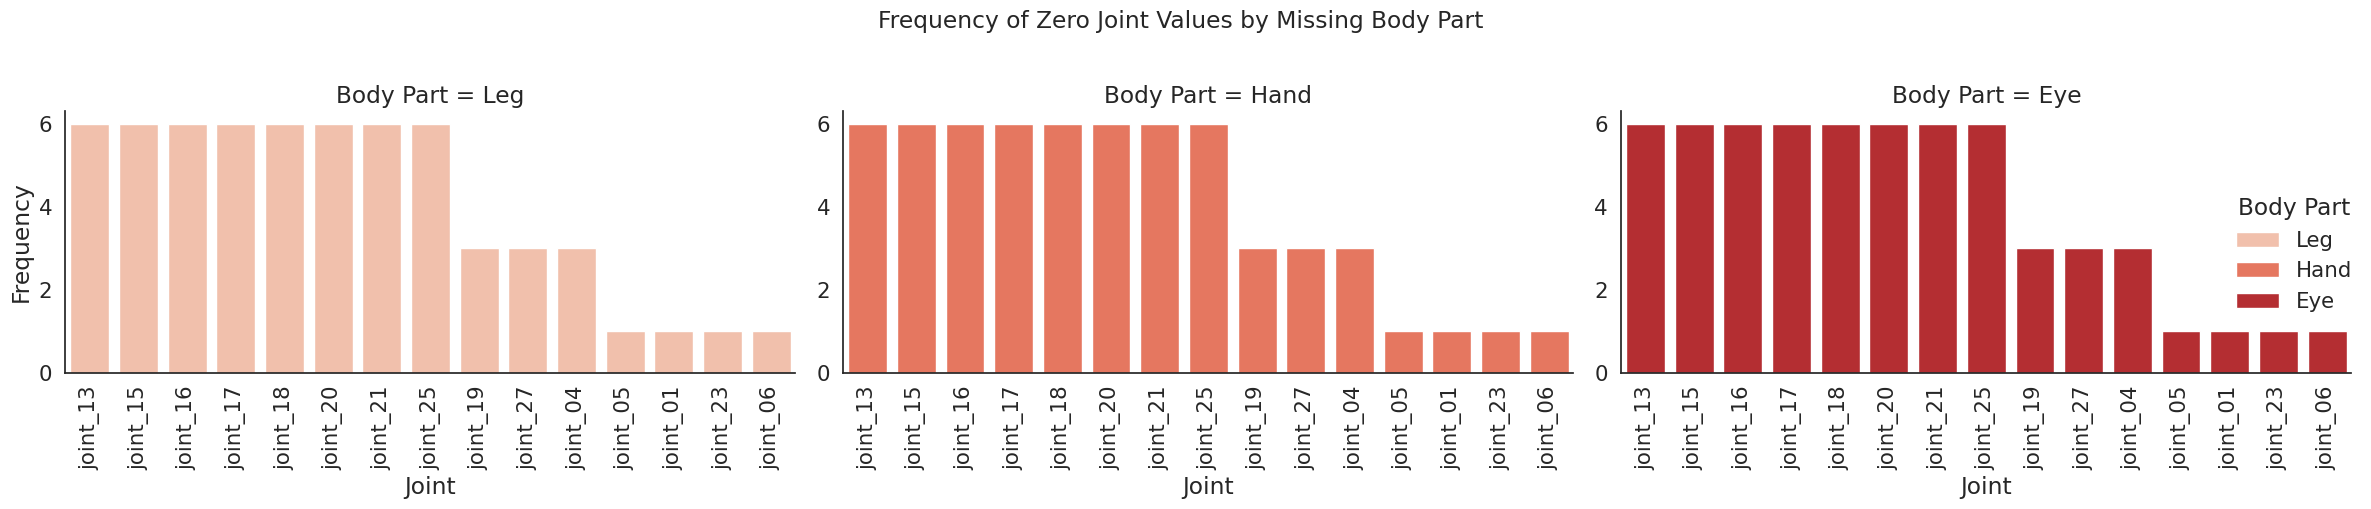

In [11]:
# ====================================================================
# VISUALIZE CORRELATIONS BETWEEN MISSING BODY PARTS AND ZERO JOINT VALUES
# ====================================================================

# Aggregate the zero joint information
agg_data = {'Leg': [], 'Hand': [], 'Eye': []}

pirates_with_one_missing = train_df[(train_df['n_legs'] == 1) |
                                      (train_df['n_hands'] == 1) |
                                      (train_df['n_eyes'] == 1)]

for sample_index, pirate_data in pirates_with_one_missing.groupby('sample_index'):
    joint_cols = [col for col in pirate_data.columns if 'joint_' in col]
    zero_joints = pirate_data[joint_cols].columns[(pirate_data[joint_cols] == 0).any()].tolist()

    # Determine which body part(s) are missing for this pirate
    missing_parts = []
    if pirate_data['n_legs'].iloc[0] == 1:
        missing_parts.append('Leg')
    if pirate_data['n_hands'].iloc[0] == 1:
        missing_parts.append('Hand')
    if pirate_data['n_eyes'].iloc[0] == 1:
        missing_parts.append('Eye')

    # Append the zero joints to the corresponding missing body part lists
    for part in missing_parts:
        agg_data[part].extend(zero_joints)

# Count the occurrences of each zero joint for each missing body part
agg_counts = {part: pd.Series(joints).value_counts() for part, joints in agg_data.items()}

# Prepare data for a single plot with faceting
plot_data = []
for part, counts in agg_counts.items():
    for joint, freq in counts.items():
        plot_data.append({'Body Part': part, 'Joint': joint, 'Frequency': freq})

plot_df = pd.DataFrame(plot_data)

# Create a single plot with faceting and a color palette starting from red
g = sns.catplot(
    data=plot_df,
    x='Joint',
    y='Frequency',
    col='Body Part',
    hue='Body Part', # Use hue to differentiate colors by Body Part
    kind='bar',
    sharey=False,
    height=5,
    aspect=1.5,
    palette='Reds' # Use a color palette starting from red
)

# Rotate x-axis labels for better readability
g.set_xticklabels(rotation=90)
g.fig.suptitle('Frequency of Zero Joint Values by Missing Body Part', y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# ====================================================================
# MIN MAX NORMALIZATION
# ====================================================================
columns_joint=train_df.columns[9:39]
train_df[columns_joint]=(train_df[columns_joint]-train_df[columns_joint].min())/(train_df[columns_joint].max()-train_df[columns_joint].min())
columns_joint=test_df.columns[9:39]
test_df[columns_joint]=(test_df[columns_joint]-test_df[columns_joint].min())/(test_df[columns_joint].max()-test_df[columns_joint].min())


In [13]:
# ====================================================================
# SPLIT DATASET IN TRAINING AND VALIDATION (Stratified Split)
# ====================================================================

# Merge train_df with labels_df to get labels for each sample_index
train_df_with_labels = pd.merge(train_df, labels_df, on='sample_index', how='left')

# Get unique pirates and their corresponding labels
unique_pirates_with_labels = train_df_with_labels[['sample_index', 'label']].drop_duplicates()

# Define the number of users for validation
N_VAL_PIRATES = 130


#train test split to stratify pirates equally in training and validation
train_pirates, val_pirates = train_test_split(
    unique_pirates_with_labels['sample_index'],
    test_size=N_VAL_PIRATES,
    stratify=unique_pirates_with_labels['label'],
    random_state=SEED
)

# Split the dataset into training, validation with previous results
train_df_split = train_df[train_df['sample_index'].isin(train_pirates)]
val_df_split = train_df[train_df['sample_index'].isin(val_pirates)]
test_df_split = test_df

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {train_df_split.shape}')
print(f'Validation set shape: {val_df_split.shape}')
print(f'Test set shape: {test_df_split.shape}')


#PAIN DISTRIBUTION IN SPLITS
print("\nLabel distribution in Training set:")
train_label_counts = train_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
train_total_pirates = train_label_counts.sum()
pain_map = {
    'no_pain':0,
    'low_pain':0,
    'high_pain':0
}
for label, count in train_label_counts.items():
    pain_map[label] = count
    percentage = (count / train_total_pirates) * 100
    print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")
print(pain_map)

#calculating class weights for unbalanced dataset

pain_class_weights = {
    'no_pain':0,
    'low_pain':0,
    'high_pain':0
}

NUMBER_OF_PAIN_CLASSES=3

for pain_class in pain_map:
  pain_class_weights[pain_class] = (train_total_pirates/(NUMBER_OF_PAIN_CLASSES*pain_map[pain_class])).astype(np.float32)
print(pain_class_weights)

#creating list useful later for tensor transformation
pain_class_weights_list=list(pain_class_weights.values())

#for pain_class in pain_class_weights:
# pain_class_weights[pain_class]=(pain_class_weights[pain_class])/(max(list(pain_class_weights.values())))
#print(pain_class_weights)

print("\nLabel distribution in Validation set:")

val_label_counts = val_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
val_total_pirates = val_label_counts.sum()
for label, count in val_label_counts.items():
    percentage = (count / val_total_pirates) * 100
    print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")
test_df_split.head()

Training set shape: (84960, 40)
Validation set shape: (20800, 40)
Test set shape: (211840, 40)

Label distribution in Training set:
no_pain: 410 pirates (77.21%)
low_pain: 76 pirates (14.31%)
high_pain: 45 pirates (8.47%)
{'no_pain': 410.0, 'low_pain': 76.0, 'high_pain': 45.0}
{'no_pain': np.float32(0.43170732), 'low_pain': np.float32(2.3289473), 'high_pain': np.float32(3.9333334)}

Label distribution in Validation set:
no_pain: 101 pirates (77.69%)
low_pain: 18 pirates (13.85%)
high_pain: 11 pirates (8.46%)


,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,2,2,2,2,2,2,0.561563,...,0.000003,0.000033,0.000048,0.000027,0.000406,0.014909,0.045098,0.012882,0.010178,0.5
1,0,1,2,2,2,2,2,2,2,0.599088,...,0.000003,0.000033,0.000060,0.000021,0.000176,0.053679,0.055375,0.013892,0.029085,0.5
2,0,2,2,2,2,2,2,2,2,0.638365,...,0.000009,0.000033,0.000146,0.000031,0.000049,0.042305,0.039620,0.016286,0.040638,0.5
3,0,3,1,2,2,2,2,2,2,0.554938,...,0.000006,0.000033,0.000047,0.000032,0.000088,0.037477,0.031101,0.008568,0.018730,0.5
4,0,4,2,2,2,0,2,2,2,0.537192,...,0.000008,0.000045,0.000047,0.000021,0.000048,0.015210,0.019426,0.008189,0.013444,0.5


In [14]:
# ====================================================================
# Create SEQUENCES grouped by pirates
# ====================================================================


def create_sequences(df, sequence_length=160, stride=0):
    """
    Creates sequences of data for each sample_index.

    Args:
        df (pd.DataFrame): The input DataFrame with 'sample_index', 'time', and features.
        sequence_length (int): The desired length of each sequence.

    Returns:
        list: A list of sequences, where each sequence is a NumPy array with dtype float32.
    """
    sequences = []


    for sample_index, group in df.groupby('sample_index'):
        # Ensure each sample has the expected number of time steps
        # Drop 'sample_index' and 'time' columns and convert to NumPy array
        if df is train_df_split or df is val_df_split:
          sequence = group.drop(columns=['sample_index', 'time']).values.astype(np.float32) # Explicitly cast to float32
        else:
          sequence = group.drop(columns=['sample_index', 'time']).values.astype(np.float32) # Explicitly cast to float32
        sequences.append(sequence)
        # sequences = np.array(sequences) # Moved this line outside the loop

    sequences = np.array(sequences) # Convert to NumPy array after appending all sequences
    return sequences

# Create sequences for training data
train_sequences = create_sequences(train_df_split)
print(f"Created {len(train_sequences)} training sequences.")


# Create sequences for validation data
val_sequences = create_sequences(val_df_split)
print(f"Created {len(val_sequences)} validation sequences.")


# Create sequences for test data
test_sequences = create_sequences(test_df_split)
print(f"Created {len(test_sequences)} test sequences.")

Created 531 training sequences.
Created 130 validation sequences.
Created 1324 test sequences.


In [15]:
# ====================================================================
# CONVERSION TO TENSORS
# ====================================================================

#print shape of sequences
print(train_sequences.shape)
print(val_sequences.shape)
print(test_sequences.shape)

#create numpy arrays of labels for training and validation sets
train_labels = labels_df[labels_df['sample_index'].isin(train_pirates)]['target'].values
validation_labels = labels_df[labels_df['sample_index'].isin(val_pirates)]['target'].values

# Convert numpy arrays to PyTorch datasets
# Ensure labels are converted to a supported integer type (like int64)
train_ds = TensorDataset(torch.from_numpy(train_sequences), torch.from_numpy(train_labels).long())
val_ds   = TensorDataset(torch.from_numpy(val_sequences), torch.from_numpy(validation_labels).long())
test_ds  = TensorDataset(torch.from_numpy(test_sequences))
pain_class_weights_ds = torch.tensor(pain_class_weights_list).to(device)

#verify the conversion
print(f"Type of pain_class_weights_ds: {type(pain_class_weights_ds)}")
print(f"Type of train_ds: {type(train_ds)}")
print(f"Type of val_ds: {type(val_ds)}")
print(f"Type of test_ds: {type(test_ds)}")
print(f"Shape of train_ds: {train_ds[0][0].shape}")
print(val_ds[0][0].dtype)
print(pain_class_weights_ds[0].dtype)



(531, 160, 38)
(130, 160, 38)
(1324, 160, 38)
Type of pain_class_weights_ds: <class 'torch.Tensor'>
Type of train_ds: <class 'torch.utils.data.dataset.TensorDataset'>
Type of val_ds: <class 'torch.utils.data.dataset.TensorDataset'>
Type of test_ds: <class 'torch.utils.data.dataset.TensorDataset'>
Shape of train_ds: torch.Size([160, 38])
torch.float32
torch.float32


In [16]:
# Define the input shape based on the training data
input_shape = train_sequences.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(train_labels))

In [17]:
# Get the first sequence tensor from train_ds
first_train_sequence_tensor = train_ds[0][0]
print(train_ds[0])

# Convert the tensor to a NumPy array and then to a pandas DataFrame
# We need to get the original column names excluding 'sample_index' and 'time'
feature_columns = [col for col in train_df_split.columns if col not in ['sample_index', 'time']]
first_train_sequence_df = pd.DataFrame(first_train_sequence_tensor.numpy(), columns=feature_columns)

print("First sequence from train_ds (showing columns):")
display(first_train_sequence_df.head())

print("-" * 30)

# Get the first sequence tensor from val_ds
first_val_sequence_tensor = val_ds[0][0]
first_val_sequence_df = pd.DataFrame(first_val_sequence_tensor.numpy(), columns=feature_columns)

print("First sequence from val_ds (showing columns):")
display(first_val_sequence_df.head())

print("-" * 30)

# Get the first sequence tensor from test_ds
first_test_sequence_tensor = test_ds[0][0]
# Note: test_df_split might have more columns than train_df_split if labels were merged into train_df_split
# Let's use the columns from the original test_df without sample_index and time for clarity
test_feature_columns = [col for col in test_df_split.columns if col not in ['sample_index','time']]
first_test_sequence_df = pd.DataFrame(first_test_sequence_tensor.numpy(), columns=test_feature_columns)


print("First sequence from test_ds (showing columns):")
display(first_test_sequence_df.head())

(tensor([[2.0000, 0.0000, 2.0000,  ..., 0.0190, 0.0203, 0.5000],
        [2.0000, 2.0000, 2.0000,  ..., 0.0095, 0.0100, 0.5000],
        [2.0000, 0.0000, 2.0000,  ..., 0.0171, 0.0169, 0.5000],
        ...,
        [2.0000, 2.0000, 2.0000,  ..., 0.0288, 0.0163, 0.5000],
        [2.0000, 1.0000, 2.0000,  ..., 0.0270, 0.0158, 0.5000],
        [2.0000, 2.0000, 2.0000,  ..., 0.0260, 0.0125, 0.5000]]), tensor(0))
First sequence from train_ds (showing columns):


,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,2.0,0.0,2.0,1.0,2.0,2.0,2.0,0.777507,0.738252,0.779512,...,2.426544e-06,1.374706e-06,0.000015,3.162814e-04,0.000004,0.014214,0.011376,0.018978,0.020291,0.5
1,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.806256,0.765147,0.761153,...,2.757563e-07,4.026520e-07,0.000022,9.828599e-07,0.000000,0.010748,0.000000,0.009473,0.010006,0.5
2,2.0,0.0,2.0,2.0,2.0,2.0,2.0,0.767592,0.721439,0.772834,...,1.063529e-07,1.440847e-08,0.000005,6.626013e-05,0.000003,0.013097,0.006830,0.017065,0.016856,0.5
3,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.666220,0.810416,0.763971,...,6.981461e-06,3.065580e-07,0.000007,1.199337e-06,0.000000,0.009505,0.006274,0.020264,0.017981,0.5
4,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.774297,0.773366,0.772162,...,3.076737e-06,1.723862e-08,0.000006,1.307199e-06,0.000007,0.004216,0.002132,0.023389,0.018477,0.5


------------------------------
First sequence from val_ds (showing columns):


,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,1.0,2.0,1.0,0.0,2.0,2.0,2.0,0.609571,0.546744,0.750767,...,0.000040,0.000290,0.000897,0.000000e+00,0.000304,0.061560,0.119068,0.035822,0.030408,0.5
1,1.0,2.0,1.0,2.0,2.0,2.0,2.0,0.664969,0.548165,0.824199,...,0.000883,0.000041,0.002277,1.096598e-07,0.001184,0.093644,0.077527,0.042603,0.019168,0.5
2,1.0,2.0,1.0,0.0,2.0,2.0,2.0,0.640547,0.540534,0.764329,...,0.000113,0.000166,0.002004,3.558279e-04,0.000000,0.167580,0.156860,0.033902,0.056776,0.5
3,0.0,1.0,1.0,1.0,2.0,2.0,2.0,0.648213,0.621127,0.726200,...,0.000351,0.000048,0.001227,2.892257e-05,0.000101,0.291602,0.359360,0.033126,0.031422,0.5
4,1.0,2.0,2.0,0.0,2.0,2.0,2.0,0.616250,0.571464,0.766785,...,0.000346,0.000108,0.006724,2.190449e-04,0.000002,0.068075,0.196753,0.051188,0.037862,0.5


------------------------------
First sequence from test_ds (showing columns):


,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.561563,0.553352,0.419037,...,0.000003,0.000033,0.000048,0.000027,0.000406,0.014909,0.045098,0.012882,0.010178,0.5
1,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.599088,0.532067,0.461325,...,0.000003,0.000033,0.000060,0.000021,0.000176,0.053679,0.055375,0.013892,0.029085,0.5
2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.638365,0.583960,0.445804,...,0.000009,0.000033,0.000146,0.000031,0.000049,0.042305,0.039620,0.016286,0.040638,0.5
3,1.0,2.0,2.0,2.0,2.0,2.0,2.0,0.554938,0.488719,0.443494,...,0.000006,0.000033,0.000047,0.000032,0.000088,0.037477,0.031101,0.008568,0.018730,0.5
4,2.0,2.0,2.0,0.0,2.0,2.0,2.0,0.537192,0.528780,0.413159,...,0.000008,0.000045,0.000047,0.000021,0.000048,0.015210,0.019426,0.008189,0.013444,0.5


In [18]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 32

In [19]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [20]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [21]:
# get all batches from the training data loader and print their shapes
#to verify it works fine
for i, xb in enumerate(train_loader):
  print(f"Shape of training batch {i+1}: {xb[0].shape}")


Shape of training batch 1: torch.Size([32, 160, 38])
Shape of training batch 2: torch.Size([32, 160, 38])
Shape of training batch 3: torch.Size([32, 160, 38])
Shape of training batch 4: torch.Size([32, 160, 38])
Shape of training batch 5: torch.Size([32, 160, 38])
Shape of training batch 6: torch.Size([32, 160, 38])
Shape of training batch 7: torch.Size([32, 160, 38])
Shape of training batch 8: torch.Size([32, 160, 38])
Shape of training batch 9: torch.Size([32, 160, 38])
Shape of training batch 10: torch.Size([32, 160, 38])
Shape of training batch 11: torch.Size([32, 160, 38])
Shape of training batch 12: torch.Size([32, 160, 38])
Shape of training batch 13: torch.Size([32, 160, 38])
Shape of training batch 14: torch.Size([32, 160, 38])
Shape of training batch 15: torch.Size([32, 160, 38])
Shape of training batch 16: torch.Size([32, 160, 38])
Shape of training batch 17: torch.Size([19, 160, 38])


In [22]:
# Iterate through the train_loader to get batches of inputs and targets
for inputs, targets in train_loader:
    # Print the shapes of the inputs and targets for the first batch
    print(f"Shape of inputs batch: {inputs.shape}")
    print(f"Shape of targets batch: {targets.shape}")

    # Break after the first batch to avoid printing for all batches
    break

Shape of inputs batch: torch.Size([32, 160, 38])
Shape of targets batch: torch.Size([32])


In [23]:
# Get the first batch from the train_loader
# This batch contains a tuple: (inputs_batch, targets_batch)
first_batch_inputs, first_batch_targets = next(iter(train_loader))

# Take the first sequence and its label from the batch
first_sequence_tensor = first_batch_inputs[0]
first_label_tensor = first_batch_targets[0]

# Convert the first sequence tensor to a pandas DataFrame for display
# Need to get the original column names excluding 'sample_index' and 'time' from the training data
feature_columns = [col for col in train_df_split.columns if col not in ['sample_index', 'time']]
first_sequence_df = pd.DataFrame(first_sequence_tensor.numpy(), columns=feature_columns)

print("First sequence from the first training batch (table format):")
display(first_sequence_df)

print("\nCorresponding label for the first sequence:")
print(first_label_tensor.item()) # Use .item() to get the scalar value from a single-element tensor

First sequence from the first training batch (table format):


,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,joint_01,joint_02,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,0.692834,0.689556,0.771917,...,9.610014e-06,9.081958e-05,4.377270e-03,0.000261,0.000219,0.005003,0.003931,0.000000,0.004168,0.5
1,1.0,2.0,2.0,2.0,2.0,2.0,2.0,0.724099,0.679592,0.781379,...,6.056707e-06,1.526239e-04,4.153936e-03,0.000241,0.000175,0.018004,0.002127,0.004902,0.004665,0.5
2,0.0,2.0,2.0,2.0,2.0,2.0,2.0,0.782437,0.694111,0.779013,...,8.475405e-08,1.549149e-05,8.701027e-04,0.000017,0.000061,0.009985,0.003176,0.003770,0.000960,0.5
3,1.0,2.0,2.0,2.0,2.0,2.0,2.0,0.675077,0.751038,0.718451,...,1.392393e-06,1.098173e-05,5.688735e-03,0.000095,0.000426,0.006673,0.000000,0.001958,0.009127,0.5
4,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.729142,0.721178,0.823090,...,5.098366e-07,4.839126e-08,2.167578e-03,0.000004,0.000195,0.000103,0.000638,0.002640,0.007270,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.690183,0.704149,0.816265,...,7.426146e-05,1.371326e-04,0.000000e+00,0.000328,0.000167,0.010313,0.002558,0.001725,0.003074,0.5
156,2.0,0.0,2.0,1.0,2.0,2.0,2.0,0.752737,0.703901,0.772569,...,3.312089e-06,8.554808e-05,9.099459e-07,0.000256,0.000092,0.005963,0.003211,0.000812,0.009319,0.5
157,2.0,1.0,2.0,2.0,2.0,2.0,2.0,0.763960,0.672669,0.737780,...,1.076565e-06,9.832155e-05,1.242182e-05,0.000218,0.000152,0.003644,0.000179,0.004097,0.003570,0.5
158,2.0,2.0,2.0,2.0,2.0,2.0,2.0,0.774604,0.726448,0.830476,...,0.000000e+00,3.391343e-05,1.104908e-05,0.000076,0.000014,0.006462,0.000000,0.003169,0.009570,0.5



Corresponding label for the first sequence:
0


##**🛠️MODEL BUILDING**

In [24]:
#=================================================
#FUNZIONE SUMMARY PER RNN
#=================================================


def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [25]:
#==========================================
#    MODELLO RNN                          #
#==========================================

class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x)

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        if self.bidirectional:
            # Reshape to (num_layers, 2, batch_size, hidden_size)
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)

            # Concat last fwd (hidden[-1, 0, ...]) and bwd (hidden[-1, 1, ...])
            # Final shape: (batch_size, hidden_size * 2)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            # Take the last layer's hidden state
            # Final shape: (batch_size, hidden_size)
            hidden_to_classify = hidden[-1]

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits




## 🧮 **Network and Training Hyperparameters**

In [26]:
# Training configuration
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 10

# Architecture
HIDDEN_LAYERS = 2        # Hidden layers
HIDDEN_SIZE = 128        # Neurons per layer

# Regularisation
DROPOUT_RATE = 0.2         # Dropout probability
L1_LAMBDA = 0.0          # L1 penalty
L2_LAMBDA = 0.0          # L2 penalty

# Set up loss function and optimizer
criterion = nn.CrossEntropyLoss(weight=pain_class_weights_ds)

## 🧠 **Model Training**

In [27]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [28]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [29]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [30]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [31]:
#==========================================
#   CSV
#==========================================
csv_file = "all_models_log.csv"

# Initialize metrics tracking
training_history = {
    'train_loss': [],
    'val_loss': [],
    'train_f1': [],
    'val_f1': [],
    'val_accuracy_class_0': [],
    'val_accuracy_class_1': [],
    'val_accuracy_class_2': []
}

training_log = []

fieldnames = [
    "model_name", "epoch", "train_loss", "val_loss", "train_f1", "val_f1",
    "l1_lambda", "l2_lambda", "patience", "evaluation_metric",
    "accuracy_nopain", "accuracy_lowpain", "accuracy_highpain"
]


In [32]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """



    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )


        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)
        # The accuracy per class will be calculated and logged after the training loop
        hyperparams = {
          "l1_lambda": L1_LAMBDA,
          "l2_lambda": L2_LAMBDA,
          "patience": PATIENCE,
          "evaluation_metric": evaluation_metric,
        }

        row = {
          "model_name": experiment_name,
          "epoch": epoch,
          "train_loss": train_loss,
          "val_loss": val_loss,
          "train_f1": train_f1,
          "val_f1": val_f1,
          **hyperparams,
          "accuracy_nopain": 0,      # Placeholder, will be updated later
          "accuracy_lowpain": 0,     # Placeholder, will be updated later
          "accuracy_highpain": 0     # Placeholder, will be updated later
        }
        training_log.append(row)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    #csv writing
    file_exists = os.path.exists(csv_file)

    with open(csv_file, mode='a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)

        if not file_exists:
            writer.writeheader()
        writer.writerow(row)
    return model, training_history

In [33]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=True,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name = "biLSTM"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
writer.add_graph(rnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 160, 256], [4, -1, 128]] 567,296        
classifier (Linear)       [-1, 3]                      771            
Total params: 568,067
Trainable params: 568,067
Non-trainable params: 0
-------------------------------------------------------------------------------


In [34]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="biLSTM_PROVA",
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.1050, F1 Score=0.5089 | Val: Loss=1.0928, F1 Score=0.5839
Epoch   2/500 | Train: Loss=1.0881, F1 Score=0.6912 | Val: Loss=1.0712, F1 Score=0.3857
Epoch   3/500 | Train: Loss=1.0660, F1 Score=0.6187 | Val: Loss=1.0365, F1 Score=0.3725
Epoch   4/500 | Train: Loss=1.0285, F1 Score=0.7087 | Val: Loss=1.0660, F1 Score=0.7618
Epoch   5/500 | Train: Loss=1.0376, F1 Score=0.6874 | Val: Loss=1.0140, F1 Score=0.7037
Epoch   6/500 | Train: Loss=1.0180, F1 Score=0.6436 | Val: Loss=1.0117, F1 Score=0.4306
Epoch   7/500 | Train: Loss=0.9708, F1 Score=0.6623 | Val: Loss=0.9999, F1 Score=0.6325
Epoch   8/500 | Train: Loss=0.9990, F1 Score=0.5941 | Val: Loss=0.9989, F1 Score=0.6577
Epoch   9/500 | Train: Loss=0.9666, F1 Score=0.6577 | Val: Loss=0.9902, F1 Score=0.7756
Epoch  10/500 | Train: Loss=0.9701, F1 Score=0.6790 | Val: Loss=1.0061, F1 Score=0.7732
Epoch  11/500 | Train: Loss=0.9289, F1 Score=0.7227 | Val: Loss=0.9319, F1 Score=0.6865
Epoch  12

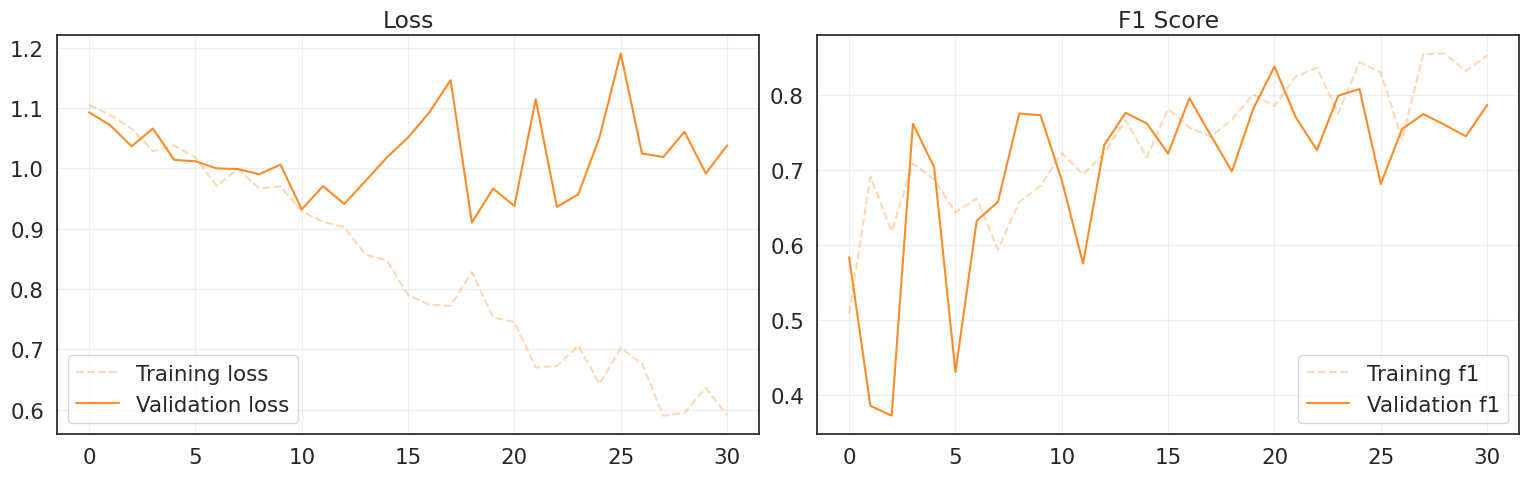

In [35]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.8308
Precision over the validation set: 0.8495
Recall over the validation set: 0.8308
F1 score over the validation set: 0.8381
✅ Accuracy values appended to all_models_log.csv


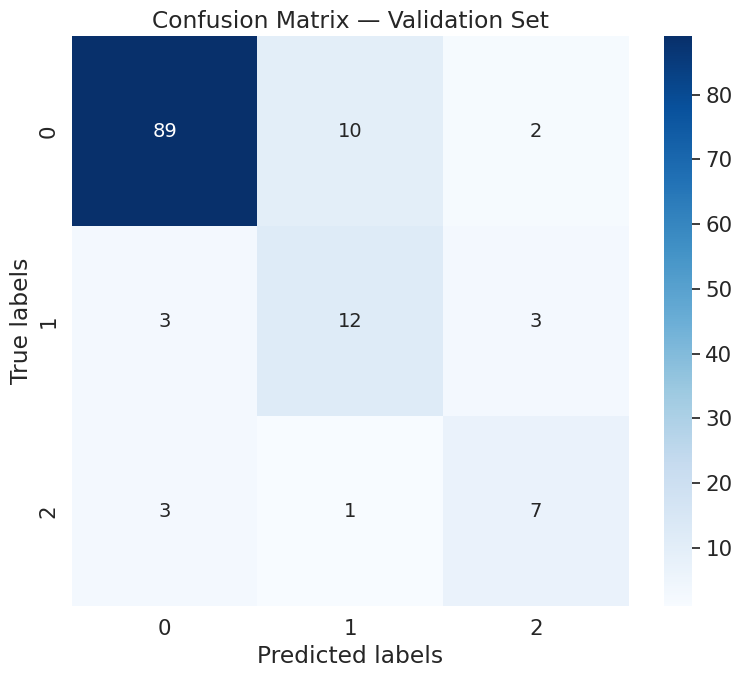

In [36]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

cm_perc = cm.astype(float) / cm.sum(axis=1)[:, None]

perc_dict = {}
for i in range(cm_perc.shape[0]):
    perc_dict[f"class_{i}_accuracy"] = cm_perc[i, i]

# Store accuracy per class with desired names
accuracy_nopain = cm_perc[0, 0] if cm.shape[0] > 0 and cm.sum(axis=1)[0] > 0 else 0
accuracy_lowpain = cm_perc[1, 1] if cm.shape[0] > 1 and cm.sum(axis=1)[1] > 0 else 0
accuracy_highpain = cm_perc[2, 2] if cm.shape[0] > 2 and cm.sum(axis=1)[2] > 0 else 0

# Read the existing data
try:
    with open(csv_file, mode='r', newline='') as f:
        reader = csv.DictReader(f)
        data = list(reader)
except FileNotFoundError:
    data = [] # Handle case where file doesn't exist yet

if data:
    # Get the last row
    last_row = data[-1]
    # Add the accuracy values, ensuring only defined fields are updated
    for field in ["accuracy_nopain", "accuracy_lowpain", "accuracy_highpain"]:
        if field in last_row:
            last_row[field] = locals()[field]


    # Write the data back to the CSV file
    with open(csv_file, mode='w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(data)
    print(f"✅ Accuracy values appended to {csv_file}")
else:
    print(f"❌ Could not append accuracy values to {csv_file}. File is empty or does not exist.")


# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

##**INFERENZA**


In [37]:
# Load trained model and set to evaluation mode
best_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=True,
    rnn_type='LSTM'
    ).to(device)
best_model.load_state_dict(torch.load('./models/biLSTM2.pt', map_location=device))
best_model.eval()

RecurrentClassifier(
  (rnn): LSTM(38, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)

In [38]:
xb = next(iter(test_loader))
print(type(xb))

<class 'list'>


In [39]:
# Collect predictions and ground truth labels
test_results = []
with torch.no_grad():  # Disable gradient computation for inference
    for xb in test_loader:
        xb = xb[0].to(device)
        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_results.append(preds)


# Combine all batches into single arrays
test_results = np.concatenate(test_results)

#map the integer value to a string
label_to_string = {
    0: 'no_pain',
    1: 'low_pain',
    2: 'high_pain'
}


results = pd.DataFrame({
    "sample_index": test_df_split['sample_index'].unique(),
    "label": test_results
})
results['label'] = results['label'].map(label_to_string)

#convert the result in a .csv file
results.to_csv("test_predictions.csv", index=False)
print("✅ CSV salvato come test_predictions.csv")


✅ CSV salvato come test_predictions.csv
